# Forecasting with Time Series

This notebook accompanies [the forecasting note](../../notes/time_series/forecasting.md). A forecast is a conditional statement $\hat y_{T+h\mid T}=E(y_{T+h}\mid\mathcal F_T)$ tied to a horizon and an uncertainty estimate. We (1) build simple baselines, (2) look at the smoothing parameter of simple exponential smoothing, (3) fit Holt-Winters, (4) check the AR(1) forecast-error variance formula by simulation and (5) show why exponentiating a log forecast gives the median, not the mean.

naive           MAE = 1.951
drift           MAE = 1.764
seasonal naive  MAE = 1.140
mean            MAE = 3.411


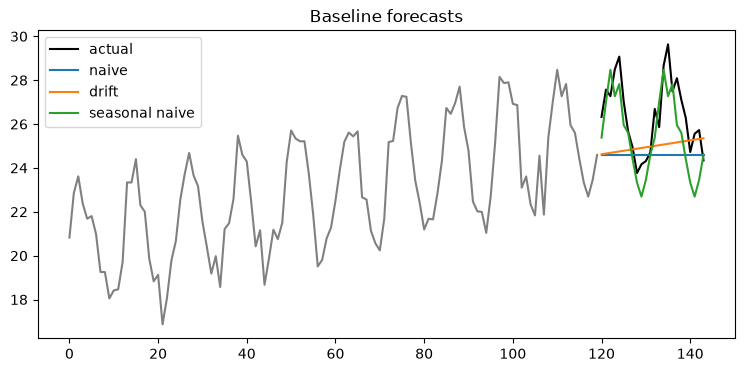

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
rng = np.random.default_rng(2024)
n, s = 144, 12
t = np.arange(n)
y = 20 + 0.05*t + 3*np.sin(2*np.pi*t/s) + rng.normal(scale=0.8, size=n)
origin, H = 120, 24
train, test = y[:origin], y[origin:origin+H]
h = np.arange(1, H+1)
naive = np.repeat(train[-1], H)
drift = train[-1] + h*(train[-1]-train[0])/(origin-1)
snaive = train[origin - s + (h-1) % s]
mean_f = np.repeat(train.mean(), H)
for name, f in [("naive",naive),("drift",drift),("seasonal naive",snaive),("mean",mean_f)]:
    print(f"{name:15s} MAE = {np.mean(np.abs(test-f)):.3f}")
plt.figure(figsize=(9,4))
plt.plot(t[:origin], train, color="0.5"); plt.plot(t[origin:origin+H], test, "k", label="actual")
for name,f in [("naive",naive),("drift",drift),("seasonal naive",snaive)]:
    plt.plot(t[origin:origin+H], f, label=name)
plt.legend(); plt.title("Baseline forecasts"); plt.show()

The series has a trend and a period-12 season, so the seasonal naive rule $\hat y_{t+h\mid t}=y_{t+h-s\lceil h/s\rceil}$ should beat the rules that ignore seasonality. The benchmark must match the structure of the series.

alpha=0.1: SSE of one-step errors = 300.1
alpha=0.5: SSE of one-step errors = 301.7
alpha=0.9: SSE of one-step errors = 411.1


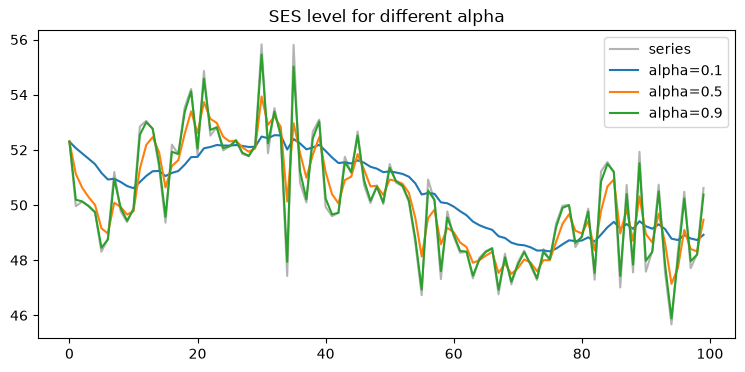

level update: 103.0


In [2]:
def ses(x, alpha, level0=None):
    level = x[0] if level0 is None else level0
    out = []
    for v in x:
        level = alpha*v + (1-alpha)*level
        out.append(level)
    return np.array(out)

noisy = 50 + np.cumsum(rng.normal(scale=0.3, size=100)) + rng.normal(scale=1.5, size=100)
plt.figure(figsize=(9,4))
plt.plot(noisy, color="0.7", label="series")
for a in (0.1, 0.5, 0.9):
    lev = ses(noisy, a)
    print(f"alpha={a}: SSE of one-step errors = {np.sum((noisy[1:]-lev[:-1])**2):.1f}")
    plt.plot(lev, label=f"alpha={a}")
plt.legend(); plt.title("SES level for different alpha"); plt.show()
# worked example from the note
print("level update:", 0.3*110 + 0.7*100)

A small $\alpha$ averages over a long history (smooth, slow); a large $\alpha$ tracks the newest observation. The worked example $\ell_t=0.3(110)+0.7(100)=103$ from the note is reproduced in the last line. Choose $\alpha$ by one-step SSE or by temporal validation, not by visual smoothness.

Holt-Winters MAE: 0.665
seasonal naive MAE: 1.14


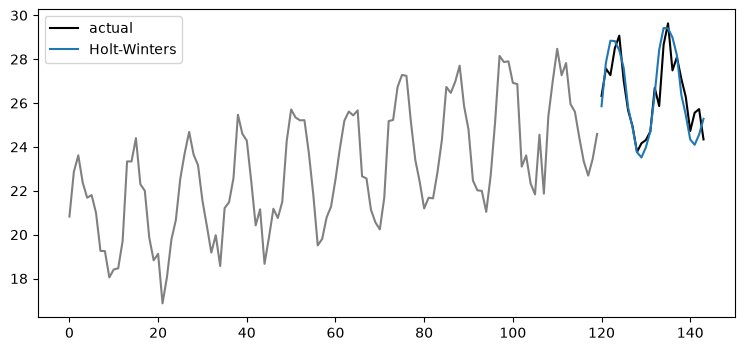

In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
fit = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=s).fit()
hw = fit.forecast(H)
print("Holt-Winters MAE:", round(np.mean(np.abs(test-hw)),3))
print("seasonal naive MAE:", round(np.mean(np.abs(test-snaive)),3))
plt.figure(figsize=(9,4))
plt.plot(t[:origin], train, color="0.5"); plt.plot(t[origin:origin+H], test, "k", label="actual")
plt.plot(t[origin:origin+H], hw, label="Holt-Winters"); plt.legend(); plt.show()

Holt-Winters keeps a level, a slope and 12 seasonal states and updates them recursively, so its forecast is $\ell_t+hb_t+s_{t+h-L\lceil h/L\rceil}$. It usually improves on seasonal naive when trend and season are stable because it averages out noise in the seasonal indices.

In [4]:
# AR(1): forecast mean phi^h*x_T and error variance sigma^2*(1-phi^{2h})/(1-phi^2)
phi, sigma, xT = 0.8, 1.0, 5.0
h_grid = np.arange(1, 9)
mean_h = phi**h_grid * xT
var_h = sigma**2*(1-phi**(2*h_grid))/(1-phi**2)
sims = np.empty((20000, len(h_grid)))
x = np.full(20000, xT)
for j in range(len(h_grid)):
    x = phi*x + rng.normal(scale=sigma, size=x.size)
    sims[:, j] = x
print("h  mean(formula)  mean(sim)  var(formula)  var(sim)")
for j,hh in enumerate(h_grid):
    print(f"{hh}  {mean_h[j]:12.4f} {sims[:,j].mean():10.4f} {var_h[j]:13.4f} {sims[:,j].var():9.4f}")
m2, v2 = mean_h[1], var_h[1]
print("95% interval at h=2:", round(m2-1.96*np.sqrt(v2),2), round(m2+1.96*np.sqrt(v2),2))

h  mean(formula)  mean(sim)  var(formula)  var(sim)
1        4.0000     4.0057        1.0000    0.9843
2        3.2000     3.1999        1.6400    1.6216
3        2.5600     2.5635        2.0496    2.0050
4        2.0480     2.0582        2.3117    2.2901
5        1.6384     1.6478        2.4795    2.4886
6        1.3107     1.3217        2.5869    2.5836
7        1.0486     1.0554        2.6556    2.6731
8        0.8389     0.8311        2.6996    2.7295
95% interval at h=2: 0.69 5.71


The simulated mean and variance match $\phi^h x_T$ and $\sigma^2\sum_{j<h}\phi^{2j}$. At $h=2$ the variance is $1.64$ and the interval is $3.2\pm2.51$. The point forecast shrinks toward the mean while the variance rises toward $\sigma^2/(1-\phi^2)=2.78$.

In [5]:
# Log transform: exp(E[log Y]) is the median, not the mean
mu, sd = 1.0, 0.8
Y = np.exp(rng.normal(mu, sd, size=200000))
print("exp(mu)             =", round(np.exp(mu),3), " sample median =", round(np.median(Y),3))
print("exp(mu + sd^2/2)    =", round(np.exp(mu+sd**2/2),3), " sample mean   =", round(Y.mean(),3))

exp(mu)             = 2.718  sample median = 2.716
exp(mu + sd^2/2)    = 3.743  sample mean   = 3.748


Under a lognormal model $E(Y)=\exp(\mu+\tfrac12\sigma^2)>\exp(\mu)$ (Jensen). State whether a reported forecast targets the mean or the median.